# Chapter 11 | Worked solutions

*Long Context, Sparse Access, and Sequence Compression*

**Goal.** Separate what a model stores, what it selects, and how attention weights the selected values. These twelve solutions progress from hand calculations to executable causal checks and a controlled experiment design. Selection can find the right row and still change the output; a summary can preserve a useful average while losing an exact fact.

**Setup.** Open this notebook inside `transformers-book`, install `requirements.txt`, and run the cells in order with a Python kernel. All calculations run on CPU. Positions in Exercises 1–4 start at one; Python indices in Exercises 5–8 and 10 start at zero. The small NumPy models illustrate mechanisms rather than reproduce a production model.

**Steps and checks.** Work out the answer first, then use the recorded calculations and assertions to check it. Both companion PDFs are exported from this notebook: the written version contains every explanation and figure; the Python version also contains code and outputs.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch11_long_context" / "model.py"
    )
    if model_path.is_file():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )
from examples.ch11_long_context.model import local_mask
from examples.ch04_attention.attention import scaled_dot_product_attention
from IPython.display import display, Image as NotebookImage
from io import BytesIO
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 11, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})


## 1. Count the grid

Each row asks a question and each column identifies a key it may read. The diagonal is allowed: a token can read itself. With six positions, the full bidirectional grid has six reads in each of six rows, or $6\times6=36$ pairs. The causal grid has row counts $1,2,3,4,5,6$, totaling $21$. The last causal query can read every position, 1 through 6.

At radius one, local queries read their immediate neighbors and themselves. The first and last positions have only one neighbor; the four interior positions have two. Thus $2+4(3)+2=16$ pairs. These are **logical permissions**. Constructing a dense grid and masking it does not by itself save the dot products.

Bidirectional row counts: [6, 6, 6, 6, 6, 6]
Causal row counts: [1, 2, 3, 4, 5, 6]
Local, radius 1 row counts: [2, 3, 3, 3, 3, 2]


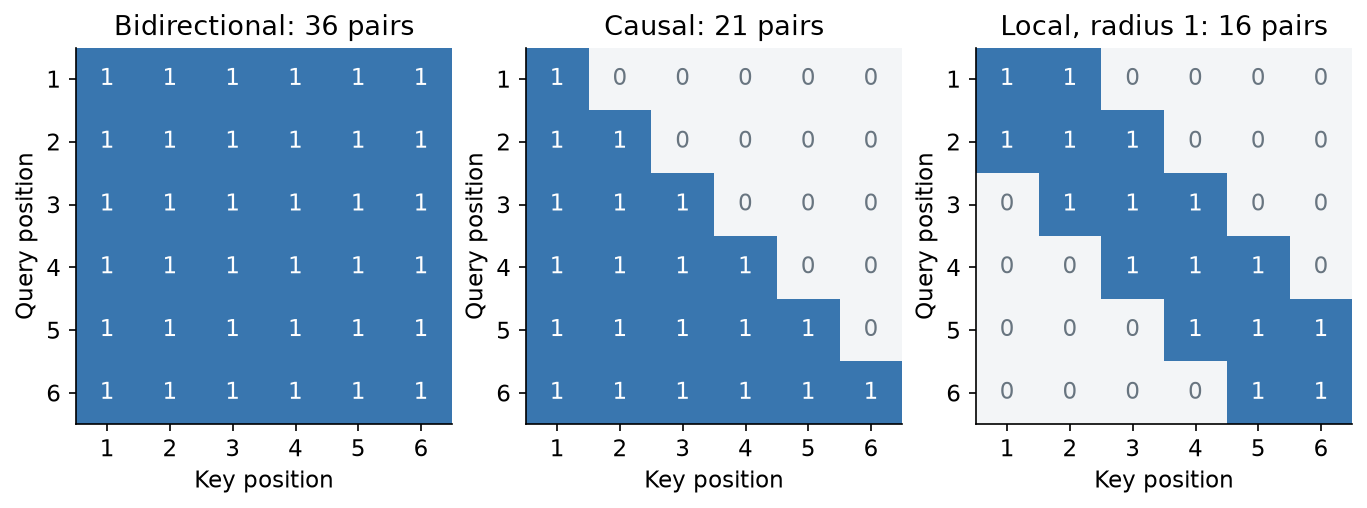

In [2]:
from matplotlib.colors import ListedColormap
positions = np.arange(6)
grids = [np.ones((6, 6), dtype=bool),
         positions[None, :] <= positions[:, None], local_mask(6, 1)]
names = ["Bidirectional", "Causal", "Local, radius 1"]
fig, axes = plt.subplots(1, 3, figsize=(9, 3.5), constrained_layout=True)
for ax, mask, name, expected in zip(axes, grids, names, (36, 21, 16)):
    assert int(mask.sum()) == expected
    ax.imshow(mask, vmin=0, vmax=1, cmap=ListedColormap(["#f3f5f7", "#3976af"]))
    for row, col in np.ndindex(mask.shape):
        ax.text(col, row, int(mask[row, col]), ha="center", va="center",
                color="white" if mask[row, col] else "#687580")
    ax.set(xticks=positions, xticklabels=positions + 1,
           yticks=positions, yticklabels=positions + 1,
           xlabel="Key position", ylabel="Query position",
           title=f"{name}: {expected} pairs")
    print(name, "row counts:", mask.sum(axis=1).tolist())
plot_buffer = BytesIO()
fig.savefig(plot_buffer, format="png", dpi=150, bbox_inches="tight")
display(NotebookImage(data=plot_buffer.getvalue()))
plt.close(fig)

The numbered cells make the boundary cases visible: the causal triangle grows down the rows, while the local band loses a neighbor at each end.

## 2. Trace a relay

Position 5 is global, so its query can read position 2 despite the gap. In the next layer, position 9 can read the updated representation at global position 5. If $h_i^{(\ell)}$ is the representation at position $i$ after layer $\ell$, the route is

$$h_2^{(0)}\longrightarrow h_5^{(1)}\longrightarrow h_9^{(2)}.$$

All queries in one layer read that layer's input representations. Position 9 cannot read the newly updated $h_5^{(1)}$ within layer 1; it must wait for layer 2. With local reads alone, each layer advances information by at most one position. The route $2,3,4,5,6,7,8,9$ needs seven layers. A route permits information to flow; learned weights determine whether it is retained.

Both relay links also obey causality: query 5 reads earlier key 2, and query 9 reads earlier key 5. If only position 1 is global, a bidirectional encoder could use $2\to1\to9$, but a causal decoder cannot: query 1 is forbidden to read future key 2. The location of a global marker matters.

In [3]:
# Convert one-based positions in the question to zero-based indices.
causal_relay = local_mask(10, 1, global_positions=(4,), causal=True)
assert causal_relay[4, 1] and causal_relay[8, 4]
early_global = local_mask(10, 1, global_positions=(0,), causal=True)
assert not early_global[0, 1]
print("Causal relay 2 -> 5 -> 9: permitted; minimum local depth:", 9 - 2)
print("Causal relay 2 -> 1 -> 9: blocked at the first read")

Causal relay 2 -> 5 -> 9: permitted; minimum local depth: 7
Causal relay 2 -> 1 -> 9: blocked at the first read


## 3. Choose, then weight

The index scores rank positions as $4,1,3,2$. The top two are therefore position 4 (score 1.9) and position 1 (score 1.4), in that order. Their main scores are $(0,\log2)$, so the exponentials are $(1,2)$ and the weights are $(1/3,2/3)$. Multiply these by the corresponding value rows:

$$\frac13(3,0)+\frac23(0,3)=(1,2).$$

Position 4 ranked first during selection but receives the smaller main attention weight. The indexer decides which rows enter the calculation; the main scores determine their contributions.

In [4]:
index_scores = np.array([1.4, 0.6, 1.0, 1.9])
selected = np.argsort(-index_scores, kind="stable")[:2]
weights = np.exp([0.0, np.log(2.0)]) / 3
answer = weights @ np.array([[3.0, 0.0], [0.0, 3.0]])
np.testing.assert_array_equal(selected, [3, 0])
np.testing.assert_allclose(answer, [1, 2])
print("Selected one-based positions:", selected + 1)
print("Main weights:", weights, "Output:", answer)

Selected one-based positions: [4 1]
Main weights: [0.33333333 0.66666667] Output: [1. 2.]


## 4. Pool one coordinate

Multiply each feature by its weight and add the products:

$$0.25(4)+0.5(0)+0.25(2)=1+0+0.5=1.5.$$

The different triple $(1,2,1)$ also gives $0.25+1+0.25=1.5$. A query receiving only this summary coordinate cannot distinguish the two source triples. Even if it knows the weights, it only knows the constraint $x_1+2x_2+x_3=6$, which many triples satisfy. It cannot recover an exact position's feature or even the block's maximum: the examples have maxima 4 and 2.

This is the tradeoff of a summary. It may retain what a task needs, but the pooled number does not preserve every possible question about its sources.

In [5]:
pool_weights = np.array([0.25, 0.5, 0.25])
for features in (np.array([4, 0, 2]), np.array([1, 2, 1])):
    summary = pool_weights @ features
    assert summary == 1.5
    print("Features:", features, "Summary:", summary,
          "Original maximum:", features.max())

Features: [4 0 2] Summary: 1.5 Original maximum: 4
Features: [1 2 1] Summary: 1.5 Original maximum: 2


## 5. Inspect a global mask

Imagine seven tokens at positions 0 through 6. A query at
position 0 can use its own key and the key immediately to its
right under a radius-one rule. Making position 3 global gives
the query another place to look even though that key is three
positions away. A **mask** records these permissions. In the
Boolean array, row $q$ belongs to query position $q$ and column
$j$ belongs to key position $j$. A true entry lets that query
read that key.

In the bidirectional rule, a pair is permitted when the query
and key are at most one position apart or either position
is global.
This opens both row 3 and column 3. Causal mode first builds
those same permissions and then keeps only the pairs with
key position $j\le q$. The causal rule applies even to the
global query and the global key.

In [6]:
from examples.ch11_long_context.model import local_mask

masks = {
    "Bidirectional": local_mask(7, 1, global_positions=(3,)),
    "Causal": local_mask(7, 1, global_positions=(3,), causal=True),
}
expected_keys = {
    "Bidirectional": [[0, 1, 3], list(range(7)), [3, 5, 6]],
    "Causal": [[0], [0, 1, 2, 3], [3, 5, 6]],
}
for name, mask in masks.items():
    print(f"{name} mask (1 = readable)")
    print("Key     0 1 2 3 4 5 6")
    for q_pos, row in enumerate(mask):
        row_bits = " ".join(str(int(bit)) for bit in row)
        print(f"Query {q_pos} {row_bits}")
    for q_pos, expected in zip((0, 3, 6), expected_keys[name]):
        readable = np.flatnonzero(mask[q_pos])
        np.testing.assert_array_equal(readable, expected)
        print(f"Keys for query {q_pos}: {readable.tolist()}")
    print()

Bidirectional mask (1 = readable)
Key     0 1 2 3 4 5 6
Query 0 1 1 0 1 0 0 0
Query 1 1 1 1 1 0 0 0
Query 2 0 1 1 1 0 0 0
Query 3 1 1 1 1 1 1 1
Query 4 0 0 0 1 1 1 0
Query 5 0 0 0 1 1 1 1
Query 6 0 0 0 1 0 1 1
Keys for query 0: [0, 1, 3]
Keys for query 3: [0, 1, 2, 3, 4, 5, 6]
Keys for query 6: [3, 5, 6]

Causal mask (1 = readable)
Key     0 1 2 3 4 5 6
Query 0 1 0 0 0 0 0 0
Query 1 1 1 0 0 0 0 0
Query 2 0 1 1 0 0 0 0
Query 3 1 1 1 1 0 0 0
Query 4 0 0 0 1 1 0 0
Query 5 0 0 0 1 1 1 0
Query 6 0 0 0 1 0 1 1
Keys for query 0: [0]
Keys for query 3: [0, 1, 2, 3]
Keys for query 6: [3, 5, 6]



For query 0, causality removes keys 1 and 3. Key 1 comes from
the local window and key 3 comes from the global column, but
both are in the future. For the global query at 3, causality
removes keys 4, 5, and 6. The query can still read keys 0
through 3, including its own key. Query 6 keeps keys 3, 5, and
6 because all three are at or before it. Earlier keys 0, 1,
2, and 4 remain outside this query's radius and are not
global. Causality removes permissions from the bidirectional
grid and never adds a read.

## 6. Filter before gathering

The largest index score, 9.0, belongs to row 3. The allowed
vector marks that row as false. The function first forms the
candidate set $\{0,1,2\}$, then ranks those candidates by
index score. The ranking is $[1,0,2]$ because
$1.1>0.8>0.6$. Thus the first two picks are rows 1 and 0.
When $k=5$, only three candidates exist. The function uses
all three and adds only row 2.

After gathering those keys and values, main attention
computes a fresh score for each selected key. The score is
the query–key dot product divided by the square root of the
key width. Here the query is $[1]$, the width is one, and the
score for each row is just its key coordinate. The index
scores determine what to gather. The main scores determine
how to mix the gathered values.

For $k=2$, the selected main scores are $(1,0)$ and their
values are $(20,10)$ in that order. Softmax exponentiates
each score and divides by the sum of the exponentials.
The weights and output are

$$
w=\frac{(e,1)}{e+1}\approx(0.731059,0.268941),
\qquad
y=\frac{20e+10}{e+1}\approx17.310586.
$$

For $k=5$, the selected main scores are $(1,0,2)$, and the
values are $(20,10,30)$. The newly admitted key gets score
$2$, the highest **main** score, even though it ranked last
among the allowed candidates. The normalization now includes
$e^2$, so the first two weights change as well.

$$
w=\frac{(e,1,e^2)}{e+1+e^2}
  \approx(0.244728,0.090031,0.665241),
\qquad
y=\frac{20e+10+30e^2}{e+1+e^2}\approx25.752104.
$$

The output is a one-coordinate vector because each value
row has width one. All positions below use zero-based
indices. The weights are reported in **selected order**.

In [7]:
from math import e

from examples.ch04_attention.attention import (
    scaled_dot_product_attention,
)
from examples.ch11_long_context.model import selected_attention

gather_query = np.array([1.0])
gather_keys = np.arange(4, dtype=float)[:, None]
gather_values = np.array([[10.0], [20.0], [30.0], [40.0]])
gather_scores = np.array([0.8, 1.1, 0.6, 9.0])
gather_allowed = np.array([True, True, True, False])

gather_expected = {
    2: ([1, 0], np.array([e, 1.0]), (20 * e + 10) / (e + 1)),
    5: ([1, 0, 2], np.array([e, 1.0, e**2]),
        (20 * e + 10 + 30 * e**2) / (e + 1 + e**2)),
}

In [8]:
gathered = {}
for budget, (indices, exp_scores, hand_output) in gather_expected.items():
    output, selected, weights = selected_attention(
        gather_query, gather_keys, gather_values,
        gather_scores, k=budget, allowed=gather_allowed,
    )
    hand_weights = exp_scores / exp_scores.sum()
    np.testing.assert_array_equal(selected, indices)
    np.testing.assert_allclose(
        weights, hand_weights, rtol=0, atol=1e-12,
    )
    np.testing.assert_allclose(
        output, [hand_output], rtol=0, atol=1e-12,
    )
    gathered[budget] = output, selected, weights
    print(f"k = {budget}")
    print(f"  Selected indices  {selected.tolist()}")
    print(f"  Main scores       {gather_keys[selected, 0].tolist()}")
    print(f"  Main weights      {np.round(weights, 8)}")
    print(f"  Output            {output[0]:.8f}")

k = 2
  Selected indices  [1, 0]
  Main scores       [1.0, 0.0]
  Main weights      [0.73105858 0.26894142]
  Output            17.31058579
k = 5
  Selected indices  [1, 0, 2]
  Main scores       [1.0, 0.0, 2.0]
  Main weights      [0.24472847 0.09003057 0.66524096]
  Output            25.75210383


With $k=5$, the gathered attention sees every allowed row.
Its output therefore agrees with dense attention with the
same mask. The dense weights are indexed in original row
order, so gather those weights at the selected indices
before comparing. The dense weight for row 3 is zero.

In [9]:
masked_out, masked_w = scaled_dot_product_attention(
    gather_query[None, :], gather_keys, gather_values,
    allowed_mask=gather_allowed,
)
output, selected, weights = gathered[5]
np.testing.assert_allclose(output, masked_out[0], rtol=0, atol=1e-12)
np.testing.assert_allclose(
    weights, masked_w[0, selected], rtol=0, atol=1e-12,
)
assert masked_w[0, 3] == 0
print("Dense weights (rows 0-3)", masked_w[0].round(8))
print("Dense output with the same mask", masked_out[0, 0].round(8))

Dense weights (rows 0-3) [0.09003057 0.24472847 0.66524096 0.        ]
Dense output with the same mask 25.75210383


## 7. Compare summary windows

Imagine writing one short note for every two tokens. A stride of
two determines when a new note is ready. An overlapping note
can refer to the preceding block as well as the current one.
Its end position still marks the same newest token. In this
example the feature values are the integers 1 through 6, and
their zero-based positions are 0 through 5.

A gate logit is a score that softmax turns into a weight. All
gate logits are zero, so in a window of $m$ positions each
exponentiated score is $e^0=1$ and each weight is $1/m$.
With one feature per token, each summary is just the mean of
the values in its window.

| End position | Positions without overlap | Mean | Positions with overlap | Mean |
| --: | :-- | --: | :-- | --: |
| 1 | 0, 1 | $(1+2)/2=1.5$ | 0, 1 | $(1+2)/2=1.5$ |
| 3 | 2, 3 | $(3+4)/2=3.5$ | 0, 1, 2, 3 | $(1+2+3+4)/4=2.5$ |
| 5 | 4, 5 | $(5+6)/2=5.5$ | 2, 3, 4, 5 | $(3+4+5+6)/4=4.5$ |

The first window ends at position 1 in either mode. It contains
two tokens because there is no preceding block at the start.
The next two overlapping windows contain four tokens each.
The first window's weights are therefore $1/2$ per position,
while each later overlapping window uses $1/4$ per position.

In [10]:
from examples.ch11_long_context.model import block_summaries

window_features = np.arange(1, 7, dtype=np.float64)[:, None]
window_logits = np.zeros_like(window_features)
window_cases = (
    (False, [1.5, 3.5, 5.5]),
    (True, [1.5, 2.5, 4.5]),
)

for overlap, expected in window_cases:
    rows, ends = block_summaries(
        window_features, window_logits, stride=2, overlap=overlap
    )
    np.testing.assert_array_equal(ends, [1, 3, 5])
    np.testing.assert_allclose(
        rows[:, 0], expected, atol=1e-12, rtol=0
    )
    print(f"Overlap {overlap}")
    print("  End positions", ends.tolist())
    print("  Summary values", rows[:, 0].tolist())

Overlap False
  End positions [1, 3, 5]
  Summary values [1.5, 3.5, 5.5]
Overlap True
  End positions [1, 3, 5]
  Summary values [1.5, 2.5, 4.5]


The output has three rows and one feature per row in both
modes. The positions $[1,3,5]$ record the end of each window.
Every completed stride block produces one summary, so the
overlapping windows change the values and the source positions
without increasing the number of summaries. An unfinished
final stride block would produce no row.

## 8. Give coordinates different gates

Now each token has two features. The first coordinate reads
$(2,0,6)$ across the three positions. The second reads
$(0,4,2)$. With stride three there is one completed window,
ending at position 2. Each coordinate forms its own weighted
sum over that same window.

Softmax exponentiates the logit in each row and divides by
the sum of exponentials in that coordinate's column.
The first gate column contains the logarithms of $(1,2,1)$,
so exponentiating recovers those numbers. Their sum is 4,
and the weights are $(1/4,2/4,1/4)$. The first summary
coordinate is

$$
\frac{1}{4}(2)+\frac{2}{4}(0)+\frac{1}{4}(6)=2.
$$

The second gate column contains the logarithms of $(3,1,2)$.
Its exponential sum is 6, giving weights $(3/6,1/6,2/6)$.
The second coordinate is

$$
\frac{3}{6}(0)+\frac{1}{6}(4)+\frac{2}{6}(2)
=\frac{8}{6}=\frac{4}{3}.
$$

The zero feature at position 1 receives half of the weight
in the first coordinate. The zero at position 0 receives
half in the second coordinate. Each contributes zero to its
sum while still using some of the weight. The weights are
determined by the gate logits, so a feature value of zero
does not remove its position from the softmax.

In [11]:
gate_features = np.array([[2., 0.], [0., 4.], [6., 2.]])
gate_numbers = np.array([[1., 3.], [2., 1.], [1., 2.]])
feature_logits = np.log(gate_numbers)

gate_rows, gate_ends = block_summaries(
    gate_features, feature_logits, stride=3
)
gate_weights = gate_numbers / gate_numbers.sum(axis=0)
gate_hand = (gate_weights * gate_features).sum(axis=0)

np.testing.assert_array_equal(gate_ends, [2])
np.testing.assert_allclose(
    gate_weights.sum(axis=0), [1., 1.], atol=1e-12, rtol=0
)
np.testing.assert_allclose(
    gate_rows, [[2., 4 / 3]], atol=1e-12, rtol=0
)
np.testing.assert_allclose(
    gate_rows[0], gate_hand, atol=1e-12, rtol=0
)

with np.printoptions(precision=8):
    print("Weights (rows are positions, columns are features)")
    print(gate_weights)
    print("Hand result", gate_hand)
    print("Helper result", gate_rows[0])
print("End positions", gate_ends.tolist())

Weights (rows are positions, columns are features)
[[0.25       0.5       ]
 [0.5        0.16666667]
 [0.25       0.33333333]]
Hand result [2.         1.33333333]
Helper result [2.         1.33333333]
End positions [2]


The helper transposes the gate array before softmax because its
softmax normalizes the last axis. That puts positions on the
axis being normalized. It transposes the weights back to match
the original feature array, multiplies entries coordinate by
coordinate, and sums over positions. The comparison uses
float64 and an absolute tolerance of $10^{-12}$ with zero
relative tolerance.

## 9. Account for three designs

A stored main-attention KV entry consists of one key and its associated value. An index score ranks a candidate, and a main read supplies an entry to attention. For one query with 128 visible positions:

| Design | Stored KV entries | Index scores | Main reads |
|---|---:|---:|---:|
| Dense | 128 | 0 | 128 |
| Select eight raw entries | 128 | 128 | 8 |
| Read stride-eight summaries + four recent entries | 20 | 0 | 20 |

Dense attention keeps and reads all raw positions. Selection still keeps all 128 because future queries may choose different rows; the indexer scans all of them before gathering eight. With stride eight there are $128/8=16$ completed summaries. Adding four raw entries gives $16+4=20$ stored entries and reads.

In one-based positions, the final summary covers 121–128 and the recent window covers 125–128. These overlapping sources do not make the cache entries identical: one summary and four raw entries occupy five separate rows. Count them separately.

These are main-cache row counts, not total system bytes. Actual storage depends on widths and precision. Persistent index features, partial-summary state, position metadata, and scratch buffers need their own accounting. Old raw data may be evicted only when all state needed for future summaries has been retained.

In [12]:
visible_positions, stride, recent = 128, 8, 4
summary_count = visible_positions // stride
counts = {"Dense": (128, 0, 128),
          "Select eight raw": (128, 128, 8),
          "Summaries + recent": (summary_count + recent, 0,
                                 summary_count + recent)}
assert counts["Summaries + recent"] == (20, 0, 20)
for design, row in counts.items():
    print(f"{design:20s} stored={row[0]:3d}, index={row[1]:3d}, reads={row[2]:3d}")

Dense                stored=128, index=  0, reads=128
Select eight raw     stored=128, index=128, reads=  8
Summaries + recent   stored= 20, index=  0, reads= 20


## 10. Check visibility and joint normalization

At query position 7, the decoder has seen the values 1 through 8.
The third stride block starts at position 6, so the decoder can
already see its first two values, 7 and 8. Its last value is at
position 8, which comes after the query. To decide whether a
query can read an entire summary, check the newest source
position in that summary.

We can build all three summaries on the completed array and
then ask which would be available to the earlier query. A zero
gate array gives equal weights over each three-token window.
Changing the value at position 8 from 9 to 90 changes only
the third window. Its mean increases by $(90-9)/3=27$.

| Source positions | End position | Original mean | New mean | Visible at query 7? |
| :-- | --: | --: | --: | :-- |
| 0, 1, 2 | 2 | $(1+2+3)/3=2$ | 2 | Yes |
| 3, 4, 5 | 5 | $(4+5+6)/3=5$ | 5 | Yes |
| 6, 7, 8 | 8 | $(7+8+9)/3=8$ | $(7+8+90)/3=35$ | No |

Causal attention permits a read when the summary's end is at
or before the query. Comparing the end positions to 7
gives the same mask after the edit because the source
positions of each window are unchanged.

In [13]:
boundary_features = np.arange(1, 10, dtype=np.float64)[:, None]
boundary_logits = np.zeros_like(boundary_features)
edited_features = boundary_features.copy()
edited_features[-1, 0] = 90.
query_position = 7

old_summaries, old_ends = block_summaries(
    boundary_features, boundary_logits, stride=3
)
new_summaries, new_ends = block_summaries(
    edited_features, boundary_logits, stride=3
)
visible_before = old_ends <= query_position
visible_after = new_ends <= query_position
np.testing.assert_array_equal(old_ends, [2, 5, 8])
np.testing.assert_array_equal(new_ends, old_ends)
np.testing.assert_array_equal(visible_before, [True, True, False])
np.testing.assert_array_equal(visible_after, visible_before)

print("End positions", new_ends.tolist())
print("Visible at position 7", visible_after.tolist())
with np.printoptions(precision=6):
    print("Original means", old_summaries[:, 0])
    print("Edited means", new_summaries[:, 0])

End positions [2, 5, 8]
Visible at position 7 [True, True, False]
Original means [2. 5. 8.]
Edited means [ 2.  5. 35.]


For these nonoverlapping windows of width three, the start
position is the end minus two. If we test starts instead,
every start passes because $0$, $3$, and $6$ are all at or
before position $7$. That admits the third summary even
though it includes the unseen value at position $8$.

In [14]:
np.testing.assert_allclose(
    old_summaries[:, 0], [2., 5., 8.], atol=1e-12, rtol=0
)
np.testing.assert_allclose(
    new_summaries[:, 0], [2., 5., 35.], atol=1e-12, rtol=0
)
np.testing.assert_allclose(
    old_summaries[visible_before], new_summaries[visible_after],
    atol=1e-12, rtol=0
)
wrong_mask = old_ends - 2 <= query_position
np.testing.assert_array_equal(wrong_mask, [True, True, True])

print("Mask based on window starts", wrong_mask.tolist())
visible_means = new_summaries[visible_after, 0]
print("Visible means with the correct mask", visible_means)
print("Edited third mean exposed by the wrong mask",
      new_summaries[wrong_mask, 0][-1])

Mask based on window starts [True, True, True]
Visible means with the correct mask [2. 5.]
Edited third mean exposed by the wrong mask 35.0


The correct mask leaves the visible summary values at $(2,5)$
in both runs. With the start-based mask the query could see a
summary that moves from 8 to 35 in response to a future edit.
Checking the end prevents that information leak. At position
8 the third block is complete and its summary can first be
read. If a decoder also has a recent raw window, it can read
the already-seen positions in the unfinished block through
that window while the summary remains unavailable.

For the joint-normalization extension, the first summary has value 2. Raw positions 6 and 7 have values 7 and 8. All three main logits are zero, so one softmax assigns weight $1/3$ to each entry:

$$y=\frac{2+7+8}{3}=\frac{17}{3}\approx5.666667.$$

Normalizing the summary branch separately gives 2. Normalizing the recent branch gives $(7+8)/2=7.5$. Averaging these outputs gives $(2+7.5)/2=4.75$. It assigns half the total weight to one summary and divides the other half between two raw entries. That is a different operation. The end-position test assumes causally computed features and gates; it cannot repair future information already mixed into them.

In [15]:
joint_values = np.array([[2.0], [7.0], [8.0]])
joint_output, joint_weights = scaled_dot_product_attention(
    np.zeros((1, 1)), joint_values, joint_values)
branch_average = (2 + (7 + 8) / 2) / 2
np.testing.assert_allclose(joint_weights, np.full((1, 3), 1 / 3))
np.testing.assert_allclose(joint_output, [[17 / 3]])
assert branch_average == 4.75
print("One joint softmax:", joint_output.item())
print("Mean of separately normalized branches:", branch_average)

One joint softmax: 5.666666666666666
Mean of separately normalized branches: 4.75


## 11. Measure missed evidence (optional)

Imagine one query looking for a fact that appears only in
row 2. Give that row a positive first value coordinate, and
set the first coordinate to zero on all four distractors.
This coordinate lets us see the effect of omitting the
target. Give distractors different second coordinates so
changes to their relative mixture are also visible.

Use the fixed width-one query $[1]$ and keys of width one.
Use natural logarithms of $(1,2,12,3,1)$ as the key coordinates.
The main scores equal those coordinates. Full attention gives
weights $(1,2,12,3,1)/19$ and output $(120/19,18/19)$
with the values below. It assigns the largest weight to
the target. We keep the query, keys, values, and available
positions fixed for the entire sweep.

In [16]:
sweep_query = np.array([1.0])
sweep_keys = np.log([1.0, 2.0, 12.0, 3.0, 1.0])[:, None]
sweep_values = np.array([
    [0.0, 1.0], [0.0, 2.0], [10.0, 0.0],
    [0.0, 4.0], [0.0, 1.0],
])
target_row = 2
dense_out, dense_w = scaled_dot_product_attention(
    sweep_query[None, :], sweep_keys, sweep_values,
)
dense_out = dense_out[0]
np.testing.assert_allclose(
    dense_out, np.array([120, 18]) / 19, rtol=0, atol=1e-12,
)
print("Dense weights (rows 0-4)", dense_w[0].round(6))
print("Dense output", dense_out.round(6))

Dense weights (rows 0-4) [0.052632 0.105263 0.631579 0.157895 0.052632]
Dense output [6.315789 0.947368]


The separate indexer gives distractors at positions 0, 1, 3,
and 4 fixed scores of $0.9$, $0.7$, $0.4$, and $0.2$.
Sweep the target index score from $0.1$ to $1.0$ and try
$k=1,2,3,5$. With a score of $0.4$, row 2 ties row 3
and wins because its index comes earlier. The target is
then ranked third and fits at $k=3$. With a score of $0.7$,
it ties row 1 and loses that tie. A budget of two still
misses the target. The main scores never change.

For every pair of target score and $k$, record the gathered
positions and whether row 2 was among them. Compare the
two-coordinate outputs using their Euclidean distance

$$
\big\lVert y_{\mathrm{selected}}-y_{\mathrm{dense}}\big\rVert_2
=\sqrt{(y_1-y_{\mathrm{dense},1})^2
      +(y_2-y_{\mathrm{dense},2})^2}.
$$

This is a distance in output space. We also print the first
coordinate so we can distinguish loss of the target from
a change in weighting when the target stays selected.

In [17]:
base_index_scores = np.array([0.9, 0.7, 0.0, 0.4, 0.2])
target_scores = (0.1, 0.4, 0.55, 0.7, 0.8, 1.0)
sweep_budgets = (1, 2, 3, 5)
sweep_rows = []
for target_score in target_scores:
    scores = base_index_scores.copy()
    scores[target_row] = target_score
    for budget in sweep_budgets:
        output, selected, _ = selected_attention(
            sweep_query, sweep_keys, sweep_values, scores, k=budget,
        )
        hit = target_row in selected
        distance = np.linalg.norm(output - dense_out)
        sweep_rows.append((
            target_score, budget, selected.tolist(),
            hit, output[0], distance,
        ))
        if not hit:
            assert output[0] == 0
        if budget == len(scores):
            np.testing.assert_allclose(
                output, dense_out, rtol=0, atol=1e-12,
            )

In [18]:
print("Score  k   Selected indices   Hit   First coord.  Distance")
for score, budget, indices, hit, first, distance in sweep_rows:
    selected_text = ",".join(map(str, indices))
    answer = "yes" if hit else "no"
    print(f"{score:>5.2f}  {budget}   {selected_text:<17} "
          f"{answer:>3}   {first:>11.6f}  {distance:>8.6f}")

Score  k   Selected indices   Hit   First coord.  Distance
 0.10  1   0                  no      0.000000  6.316009
 0.10  2   0,1                no      0.000000  6.356618
 0.10  3   0,1,3              no      0.000000  6.591363
 0.10  5   0,1,3,4,2         yes      6.315789  0.000000
 0.40  1   0                  no      0.000000  6.316009
 0.40  2   0,1                no      0.000000  6.356618
 0.40  3   0,1,2             yes      8.000000  1.792653
 0.40  5   0,1,2,3,4         yes      6.315789  0.000000
 0.55  1   0                  no      0.000000  6.316009
 0.55  2   0,1                no      0.000000  6.356618
 0.55  3   0,1,2             yes      8.000000  1.792653
 0.55  5   0,1,2,3,4         yes      6.315789  0.000000
 0.70  1   0                  no      0.000000  6.316009
 0.70  2   0,1                no      0.000000  6.356618
 0.70  3   0,1,2             yes      8.000000  1.792653
 0.70  5   0,1,2,3,4         yes      6.315789  0.000000
 0.80  1   0                 

A miss erases the target signal in the first coordinate.
For example, with a target score of $0.1$ and $k=3$,
that coordinate is zero while dense attention gives
$120/19\approx6.316$. When the target score rises to $1.0$
at $k=1$, the target is the only retained value. Its
first coordinate is now $10$. This run finds the target
but still differs from dense attention, which gives some
weight to the distractors. Keeping the target at $k=3$
with score $1.0$ retains two distractors too. The first
coordinate becomes $120/(12+1+2)=8$. At score $0.1$, raising
$k$ from one to three admits only distractors. The first
coordinate stays zero and the second moves farther from
the dense reference, so the distance grows in this case.

Two distinct mechanisms contribute to the output error.
An omitted row contributes nothing. Even when the target
is retained, softmax renormalizes across the rows that
remain. With $k=5$, all five rows contribute to both sums
in softmax attention. Changing their order leaves the
mathematical output unchanged and the NumPy results agree
within the tolerance. This controlled fixture measures
how ranking changes one attention output. A trained model's
answer quality requires a separate test on labeled tasks.

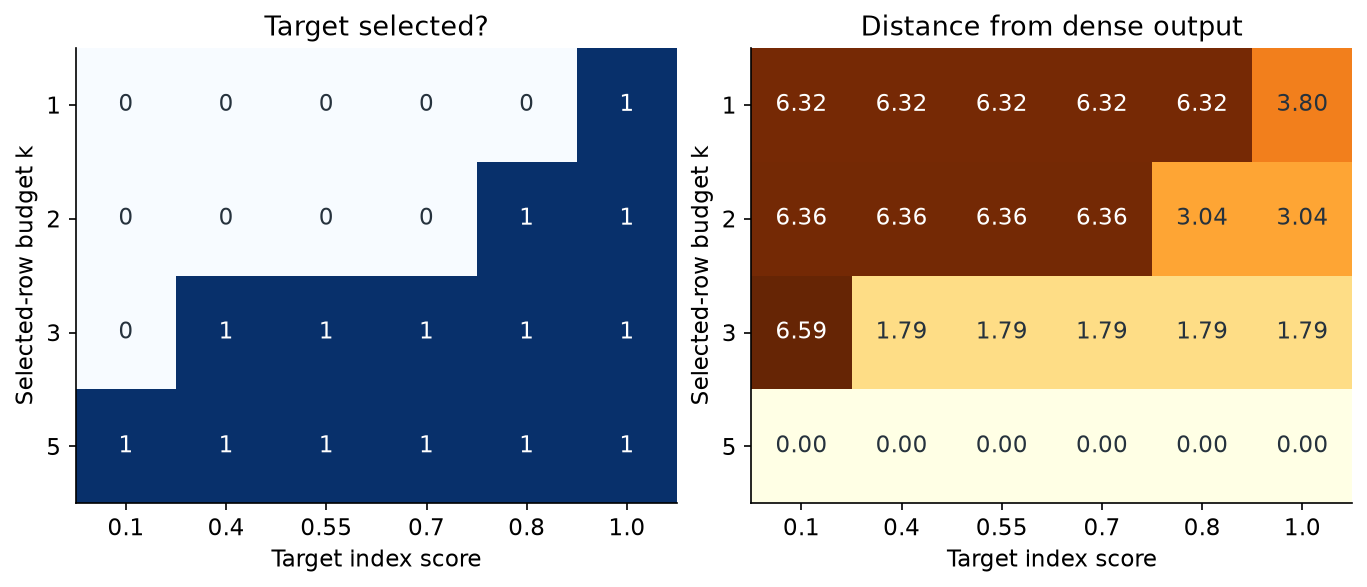

In [19]:
# Visualize the complete deterministic sweep above.
score_levels = sorted({row[0] for row in sweep_rows})
budgets = sorted({row[1] for row in sweep_rows})
hits = np.zeros((len(budgets), len(score_levels)))
errors = np.zeros_like(hits)
for score, budget, indices, hit, first, distance in sweep_rows:
    row, col = budgets.index(budget), score_levels.index(score)
    hits[row, col], errors[row, col] = int(hit), distance
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)
for ax, values, title, cmap, fmt in zip(
        axes, (hits, errors), ("Target selected?", "Distance from dense output"),
        ("Blues", "YlOrBr"), (".0f", ".2f")):
    ax.imshow(values, cmap=cmap, aspect="auto", vmin=0)
    ax.set(xticks=range(len(score_levels)), xticklabels=score_levels,
           yticks=range(len(budgets)), yticklabels=budgets,
           xlabel="Target index score", ylabel="Selected-row budget k",
           title=title)
    for row, col in np.ndindex(values.shape):
        ax.text(col, row, format(values[row, col], fmt), ha="center", va="center",
                color="white" if values[row, col] > .6 * values.max() else "#26323d")
plot_buffer = BytesIO()
fig.savefig(plot_buffer, format="png", dpi=150, bbox_inches="tight")
display(NotebookImage(data=plot_buffer.getvalue()))
plt.close(fig)

The left panel records selection as 1 (yes) or 0 (no); the right panel shows Euclidean distance in output-vector units. A hit does not imply zero error. Only selecting all five rows guarantees agreement here, because it preserves the full softmax denominator and every value contribution. More selected rows need not monotonically reduce the distance for this fixed index ranking.

## 12. Plan a long-document comparison

One workable experiment uses a registry of shipments, archives, and seal codes. The one-fact task asks for the seal of shipment R17, whose record says it uses C42. The two-fact task separates the evidence: one record links R17 to archive A03; another links A03 to C42. Ask for both the archive and the seal in the second task so finding only one fact earns partial credit rather than a correct joint answer.

Construct documents of 2,048, 8,192, and 32,768 tokens with a common tokenizer and the question at the end. For length $T$, place the one-fact record at $T/8$. For two facts, use $T/8$ and $3T/8$ and counterbalance which record comes first. Create nearby controls at $T-96$ and $T-64$, using only $T-64$ for one fact. Use short fixed-length templates, reserve room for the question, and record actual tokenized start and end positions so evidence cannot overlap the question or other evidence.

Fill the remaining document with plausible distractors. Randomize IDs and codes so the answer cannot be guessed from the question, position, or filler, and ensure each requested answer is unique. Pair near and far versions by moving the same records while preserving the question and answer. Split by underlying document **before** making variants; otherwise a near training example could leak into a far test example. Reserve 400 test documents per task and length, each with both placements. Every system receives the same test inputs and output instructions.

Use causal decoders with eight layers, equal width, the same tokenizer, positional convention, and output head. The context capacity must allow at least 32,800 tokens, including the continuation. Start shared parameters from paired initializations and train on the same documents and token budget. Fix architecture-specific settings using validation data before testing. A concrete set of policies is:

| Method | History available to a query |
|---|---|
| Dense | All current and earlier raw positions |
| Local | Current position and up to 128 earlier positions per layer; no global markers |
| Learned selection | Up to 128 raw entries, ranked by scanning all eligible raw positions |
| Sequence summaries | All completed stride-16 summaries plus 128 recent raw entries |

Train the indexer using an auxiliary ranking objective favoring annotated evidence for the answer query. Give all four models separate training prompts asking for the same supporting-record IDs, and disclose the selector's extra objective and training cost. Rank only eligible positions. For summaries, use causally computed features and require the summary's last position to be visible; count summary and raw entries separately when their source spans overlap. With eight local layers and radius 128, a path can advance at most $8(128)=1,024$ positions, so nearby and distant evidence test different access conditions. These are separately trained architectures, not a claim that masks can be swapped without adaptation.

For answer quality, decode greedily until a newline or 32 generated tokens. Require `seal=CODE` for one fact and `archive=ID seal=CODE` for two facts. Normalize surrounding whitespace and case, then score exact match for the seal, each field separately, and both fields jointly. Missing or malformed fields are incorrect. Report results by task, length, and evidence placement, with paired differences on the same underlying documents. Bootstrap whole documents if estimating uncertainty so near/far variants stay paired. For selection, record whether a key from **each** required evidence record reaches the selected set at the answer query in a specified layer and head. This measures direct access at that point; answer accuracy measures behavior after all layers.

Measure memory and latency on the same GPU at batch size one. Use float16 inference where supported and disclose actual kernel precision, device, and software. After prefill and after decoding, count live persistent bytes from array shapes and dtype sizes across all layers: raw KV, summaries, partial-summary buffers, index keys, and position metadata. Report these components and allocated capacity separately. Also measure peak temporary and total memory, including index scans, dense score arrays, and gather buffers. Log index-score counts and main-read counts independently.

Time prefill from device-ready input IDs through logits for the first continuation token, including creation of summaries and index state. For decode timing, replay the **same** continuation of 32 token IDs for all methods. Prefill supplies the first prediction; feed the first 31 IDs and time those 31 incremental calls. Include cache updates, selection, gathering, and attention. This controlled timing workload is separate from the greedy quality test, whose generated tokens can differ. Warm up, synchronize the GPU at timing boundaries, rotate method order, and run 20 trials on the same prompts. Report median prefill latency and decode milliseconds per step. If a method runs out of memory, record that result; compare speed only for methods that complete the same workload.

No benchmark scores are invented here. This is an experimental protocol: it specifies what to hold fixed, what to measure, and which conclusions each measurement supports.

**Checks and next steps.** The executed assertions check causal masks, summary visibility, pooling, joint softmax, and dense agreement when every row is selected. Try moving the global marker or changing the target rank; predict the result before running it. Keep storage, index work, main reads, and output error separate. The next chapter studies data movement while preserving the attention operation.